# Boston Housing: descriptive statistics and statistical inference
Alinazar Zharkyn

This notebook follows every task listed in the course's Project Case Scenario.
The observations are Boston-area census tracts, rather than individual houses.
MEDV is each tract's median owner-occupied home value, measured in thousands of dollars.
The significance level is 0.05. Associations in these observational data do not establish causation.

Data source: the public CSV referenced by the official course notebook. The accompanying
`boston_housing.csv` preserves that download. If it is absent, the loading cell uses the original URL.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm

DATA_URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
data_path = Path('boston_housing.csv')
raw_df = pd.read_csv(data_path if data_path.exists() else DATA_URL)
# The first column is a CSV serialization index, not a housing variable.
assert raw_df.columns[0] == 'Unnamed: 0'
assert raw_df.iloc[:, 0].tolist() == list(range(len(raw_df)))
boston_df = raw_df.drop(columns=['Unnamed: 0'])
assert boston_df.shape == (506, 13)
assert set(boston_df['CHAS'].unique()) == {0.0, 1.0}
alpha = 0.05
plt.rcParams.update({'figure.figsize': (8, 4.6), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Observations:', len(boston_df))
print('Housing variables:', len(boston_df.columns))
print('Significance level:', alpha)

Observations: 506
Housing variables: 13
Significance level: 0.05


## Task 1: Familiarize yourself with the dataset
### 1. Display the first five rows

In [2]:
print(boston_df.head().to_string(index=False))

   CRIM   ZN  INDUS  CHAS   NOX    RM  AGE    DIS  RAD   TAX  PTRATIO  LSTAT  MEDV
0.00632 18.0   2.31   0.0 0.538 6.575 65.2 4.0900  1.0 296.0     15.3   4.98  24.0
0.02731  0.0   7.07   0.0 0.469 6.421 78.9 4.9671  2.0 242.0     17.8   9.14  21.6
0.02729  0.0   7.07   0.0 0.469 7.185 61.1 4.9671  2.0 242.0     17.8   4.03  34.7
0.03237  0.0   2.18   0.0 0.458 6.998 45.8 6.0622  3.0 222.0     18.7   2.94  33.4
0.06905  0.0   2.18   0.0 0.458 7.147 54.2 6.0622  3.0 222.0     18.7   5.33  36.2


### 2. Display the data types of each column

In [3]:
print(boston_df.dtypes.to_string())

CRIM       float64
ZN         float64
INDUS      float64
CHAS       float64
NOX        float64
RM         float64
AGE        float64
DIS        float64
RAD        float64
TAX        float64
PTRATIO    float64
LSTAT      float64
MEDV       float64


### 3. Check for missing values in each column

In [4]:
missing = boston_df.isna().sum()
print(missing.to_string())
print('Total missing values:', int(missing.sum()))

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
LSTAT      0
MEDV       0
Total missing values: 0


### 4. Check for duplicate rows

In [5]:
duplicates = int(boston_df.duplicated().sum())
print('Duplicate housing rows:', duplicates)
print('Duplicate check excludes the CSV row-number column.')

Duplicate housing rows: 0
Duplicate check excludes the CSV row-number column.


### 5. Display the correlation matrix

In [6]:
correlations = boston_df.corr()
print(correlations.round(3).to_string())

          CRIM     ZN  INDUS   CHAS    NOX     RM    AGE    DIS    RAD    TAX  PTRATIO  LSTAT   MEDV
CRIM     1.000 -0.200  0.407 -0.056  0.421 -0.219  0.353 -0.380  0.626  0.583    0.290  0.456 -0.388
ZN      -0.200  1.000 -0.534 -0.043 -0.517  0.312 -0.570  0.664 -0.312 -0.315   -0.392 -0.413  0.360
INDUS    0.407 -0.534  1.000  0.063  0.764 -0.392  0.645 -0.708  0.595  0.721    0.383  0.604 -0.484
CHAS    -0.056 -0.043  0.063  1.000  0.091  0.091  0.087 -0.099 -0.007 -0.036   -0.122 -0.054  0.175
NOX      0.421 -0.517  0.764  0.091  1.000 -0.302  0.731 -0.769  0.611  0.668    0.189  0.591 -0.427
RM      -0.219  0.312 -0.392  0.091 -0.302  1.000 -0.240  0.205 -0.210 -0.292   -0.356 -0.614  0.695
AGE      0.353 -0.570  0.645  0.087  0.731 -0.240  1.000 -0.748  0.456  0.506    0.262  0.602 -0.377
DIS     -0.380  0.664 -0.708 -0.099 -0.769  0.205 -0.748  1.000 -0.495 -0.534   -0.232 -0.497  0.250
RAD      0.626 -0.312  0.595 -0.007  0.611 -0.210  0.456 -0.495  1.000  0.910    0.465  0.4

## Task 2: Generate descriptive statistics and visualizations
### 1. Display descriptive statistics

In [7]:
print(boston_df.describe().round(3).to_string())
print(f"MEDV mean: {boston_df.MEDV.mean():.3f}; median: {boston_df.MEDV.median():.3f}; standard deviation: {boston_df.MEDV.std():.3f} ($1,000).")

          CRIM       ZN    INDUS     CHAS      NOX       RM      AGE      DIS      RAD      TAX  PTRATIO    LSTAT     MEDV
count  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000  506.000
mean     3.614   11.364   11.137    0.069    0.555    6.285   68.575    3.795    9.549  408.237   18.456   12.653   22.533
std      8.602   23.322    6.860    0.254    0.116    0.703   28.149    2.106    8.707  168.537    2.165    7.141    9.197
min      0.006    0.000    0.460    0.000    0.385    3.561    2.900    1.130    1.000  187.000   12.600    1.730    5.000
25%      0.082    0.000    5.190    0.000    0.449    5.885   45.025    2.100    4.000  279.000   17.400    6.950   17.025
50%      0.257    0.000    9.690    0.000    0.538    6.208   77.500    3.207    5.000  330.000   19.050   11.360   21.200
75%      3.677   12.500   18.100    0.000    0.624    6.624   94.075    5.188   24.000  666.000   20.200   16.955   25.000
max     88.976  

### 2. Create a MEDV boxplot

The middle 50% ranges from $17,025 to $25,000; the median is $21,200.
The boxplot shows several unusually high tract medians relative to the central distribution.


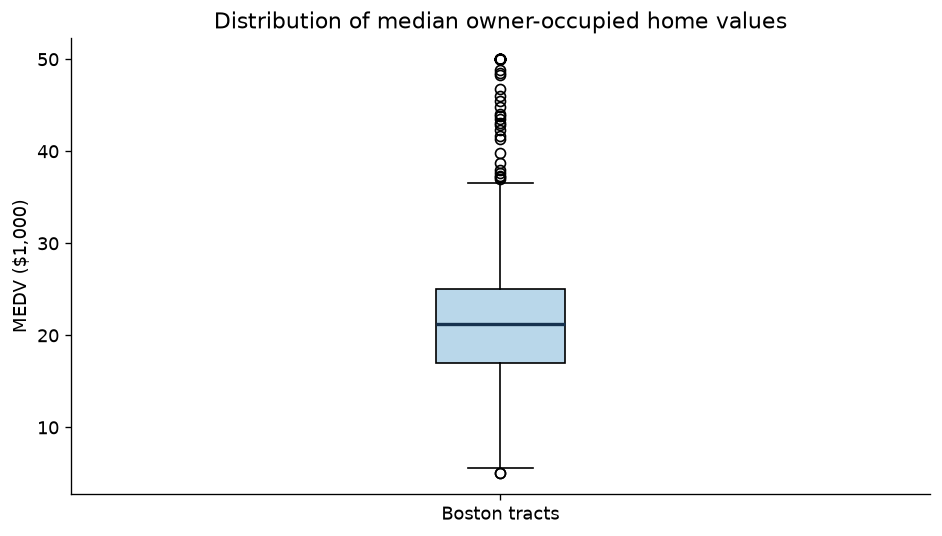

In [8]:
fig, ax = plt.subplots()
ax.boxplot(boston_df['MEDV'], tick_labels=['Boston tracts'], patch_artist=True,
           boxprops={'facecolor': '#B9D7EA'}, medianprops={'color': '#16324F', 'linewidth': 2})
ax.set(title='Distribution of median owner-occupied home values', ylabel='MEDV ($1,000)')
fig.tight_layout()
plt.show()
q1, med, q3 = boston_df.MEDV.quantile([0.25, 0.5, 0.75])
print(f'The middle 50% ranges from ${q1*1000:,.0f} to ${q3*1000:,.0f}; the median is ${med*1000:,.0f}.')
print('The boxplot shows several unusually high tract medians relative to the central distribution.')

### 3. Create a CHAS bar plot

35 of 506 tracts (6.9%) are river bounded; the groups are markedly unequal in size.


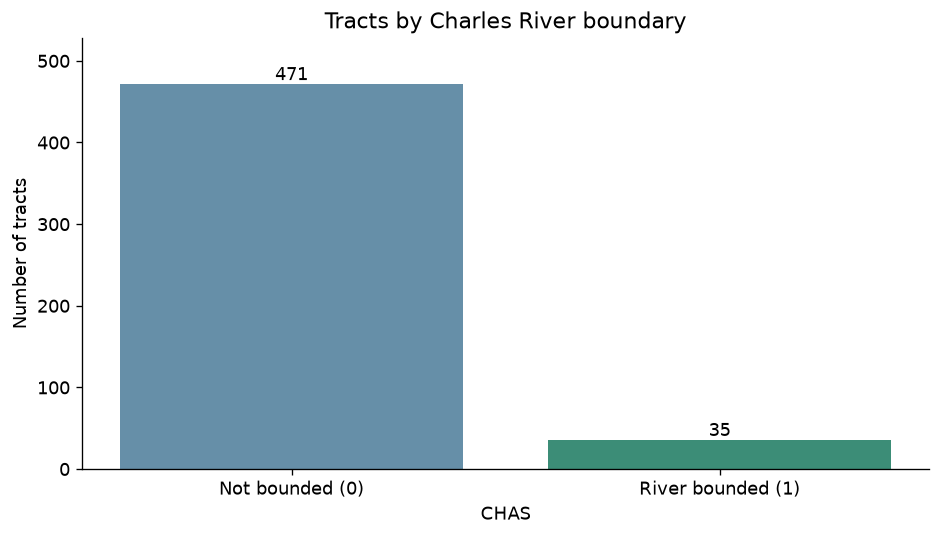

In [9]:
chas_counts = boston_df.CHAS.astype(int).value_counts().sort_index()
fig, ax = plt.subplots()
bars = ax.bar(['Not bounded (0)', 'River bounded (1)'], chas_counts.values, color=['#668FA8', '#3C8D77'])
ax.bar_label(bars)
ax.set(title='Tracts by Charles River boundary', xlabel='CHAS', ylabel='Number of tracts')
ax.set_ylim(0, chas_counts.max()*1.12)
fig.tight_layout()
plt.show()
print(f'{chas_counts[1]} of {len(boston_df)} tracts ({100*chas_counts[1]/len(boston_df):.1f}%) are river bounded; the groups are markedly unequal in size.')

### 4. Discretize AGE and compare MEDV
AGE is the percentage of owner-occupied units built before 1940. The displayed case
scenario requests three groups but does not state the cutoffs. This analysis explicitly
uses **AGE ≤ 35**, **35 < AGE < 70**, and **AGE ≥ 70**, preserving all observations.
These are groups of tract-level percentages, rather than the ages of individual houses.


               count    mean  median    std
AGE_GROUP                                  
AGE <= 35         91  27.776    24.8  7.638
35 < AGE < 70    128  24.948    22.6  6.969
AGE >= 70        287  19.793    18.2  9.515
Group medians ($1,000): {'AGE <= 35': 24.8, '35 < AGE < 70': 22.6, 'AGE >= 70': 18.2}
Tracts with a smaller proportion of pre-1940 units have higher median values in this sample; the distributions overlap.


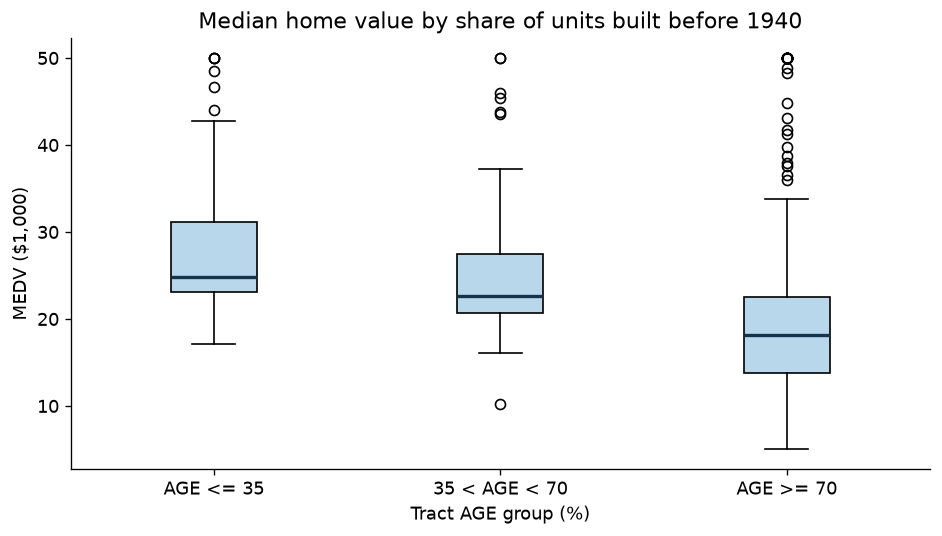

In [10]:
age_labels = ['AGE <= 35', '35 < AGE < 70', 'AGE >= 70']
boston_df['AGE_GROUP'] = pd.Categorical(
    np.select([boston_df.AGE <= 35, boston_df.AGE < 70], age_labels[:2], default=age_labels[2]),
    categories=age_labels, ordered=True)
age_groups = [boston_df.loc[boston_df.AGE_GROUP == label, 'MEDV'] for label in age_labels]
assert sum(map(len, age_groups)) == len(boston_df)
print(boston_df.groupby('AGE_GROUP', observed=True).MEDV.agg(['count', 'mean', 'median', 'std']).round(3).to_string())
fig, ax = plt.subplots()
ax.boxplot(age_groups, tick_labels=age_labels, patch_artist=True,
           boxprops={'facecolor': '#B9D7EA'}, medianprops={'color': '#16324F', 'linewidth': 2})
ax.set(title='Median home value by share of units built before 1940', xlabel='Tract AGE group (%)', ylabel='MEDV ($1,000)')
fig.tight_layout()
plt.show()
medians = [float(g.median()) for g in age_groups]
print('Group medians ($1,000):', dict(zip(age_labels, medians)))
print('Tracts with a smaller proportion of pre-1940 units have higher median values in this sample; the distributions overlap.')

### 5. Create a NOX versus INDUS scatter plot

Higher INDUS generally accompanies higher NOX. The pattern is positive, with clustering and some curvature.


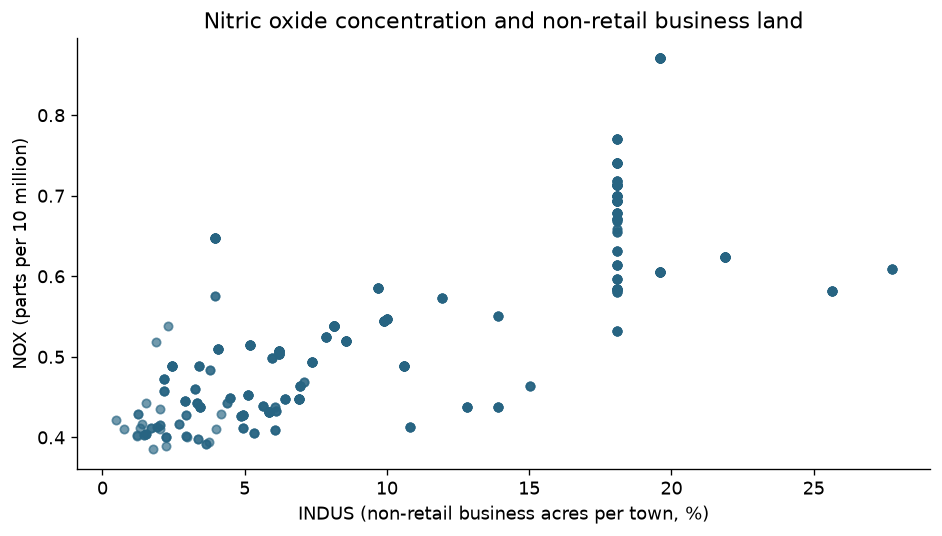

In [11]:
fig, ax = plt.subplots()
ax.scatter(boston_df.INDUS, boston_df.NOX, color='#276482', alpha=.65, s=25)
ax.set(title='Nitric oxide concentration and non-retail business land', xlabel='INDUS (non-retail business acres per town, %)', ylabel='NOX (parts per 10 million)')
fig.tight_layout()
plt.show()
print('Higher INDUS generally accompanies higher NOX. The pattern is positive, with clustering and some curvature.')

### 6. Create a PTRATIO histogram

PTRATIO ranges from 12.6 to 22.0, with median 19.05.
Ratios are concentrated toward the high end, especially around 20; the distribution is not symmetric.


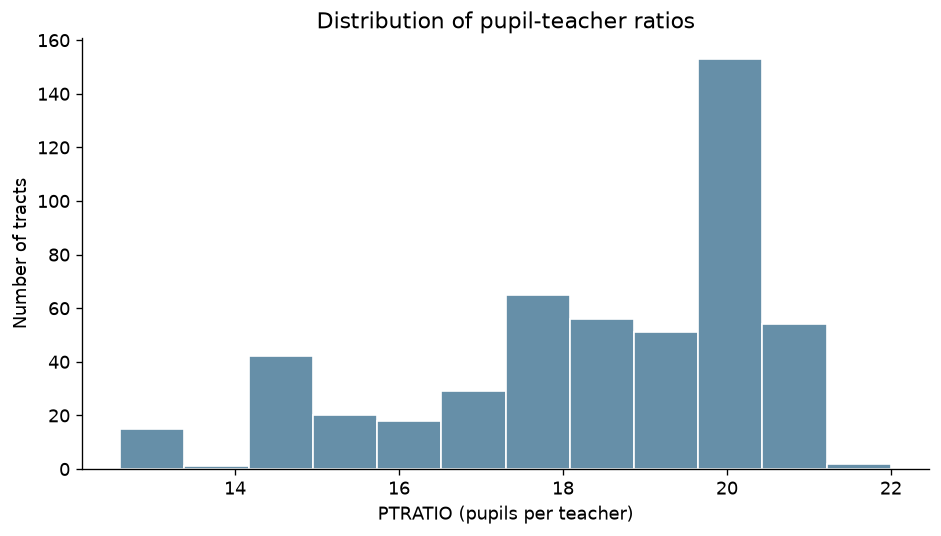

In [12]:
fig, ax = plt.subplots()
ax.hist(boston_df.PTRATIO, bins=12, color='#668FA8', edgecolor='white')
ax.set(title='Distribution of pupil-teacher ratios', xlabel='PTRATIO (pupils per teacher)', ylabel='Number of tracts')
fig.tight_layout()
plt.show()
print(f'PTRATIO ranges from {boston_df.PTRATIO.min():.1f} to {boston_df.PTRATIO.max():.1f}, with median {boston_df.PTRATIO.median():.2f}.')
print('Ratios are concentrated toward the high end, especially around 20; the distribution is not symmetric.')

## Task 3: Apply statistical tests
Each hypothesis concerns a population association or population mean. Although MEDV
contains tract medians, a t-test and ANOVA compare **means of those tract-level MEDV values**,
not the population medians directly.

### 1. Levene's test for equality of MEDV variances across CHAS groups
H0: the two population variances are equal. H1: they differ.
The median-centered version of Levene's test is used for robustness.


In [13]:
river = boston_df.loc[boston_df.CHAS == 1, 'MEDV']
nonriver = boston_df.loc[boston_df.CHAS == 0, 'MEDV']
levene_chas = stats.levene(river, nonriver, center='median')
print(f'Levene statistic = {levene_chas.statistic:.6f}; p = {levene_chas.pvalue:.8f}')
print('Reject equal variances at alpha=0.05. Use Welch rather than the pooled equal-variance t-test.')
# Mean-centered Levene is also shown to make the implementation choice transparent.
levene_mean = stats.levene(river, nonriver, center='mean')
print(f'Mean-centered Levene: statistic={levene_mean.statistic:.6f}; p={levene_mean.pvalue:.8f}. The same decision follows.')

Levene statistic = 4.590342; p = 0.03263098
Reject equal variances at alpha=0.05. Use Welch rather than the pooled equal-variance t-test.
Mean-centered Levene: statistic=8.751905; p=0.00323812. The same decision follows.


### 2. T-test for MEDV between river and nonriver tracts
H0: mean MEDV is equal in the two groups. H1: the means differ.
Use an independent, two-sided Welch t-test because the preceding variance test rejects equality.


In [14]:
ttest_chas = stats.ttest_ind(river, nonriver, equal_var=False)
ci_chas = ttest_chas.confidence_interval(confidence_level=.95)
mean_diff = float(river.mean() - nonriver.mean())
print(f'River group: n={len(river)}, mean MEDV={river.mean():.6f}')
print(f'Nonriver group: n={len(nonriver)}, mean MEDV={nonriver.mean():.6f}')
print(f't={ttest_chas.statistic:.6f}; df={ttest_chas.df:.6f}; p={ttest_chas.pvalue:.8f}')
print(f'Mean difference (river minus nonriver)={mean_diff:.6f} ($1,000); 95% CI=[{ci_chas.low:.6f}, {ci_chas.high:.6f}].')
print('Reject equal means. River-bounded tracts have significantly higher mean MEDV in this sample; this does not establish that the river caused the difference.')

River group: n=35, mean MEDV=28.440000
Nonriver group: n=471, mean MEDV=22.093843
t=3.113291; df=36.876409; p=0.00356717
Mean difference (river minus nonriver)=6.346157 ($1,000); 95% CI=[2.215483, 10.476831].
Reject equal means. River-bounded tracts have significantly higher mean MEDV in this sample; this does not establish that the river caused the difference.


### 3. ANOVA comparing MEDV among the three AGE groups
H0: all three population means are equal. H1: at least one differs.
Report the requested classical one-way ANOVA, then check variance equality and a Welch sensitivity analysis.


In [15]:
anova_age = stats.f_oneway(*age_groups)
levene_age = stats.levene(*age_groups, center='median')
welch_age = stats.f_oneway(*age_groups, equal_var=False)
print(f'Classical one-way ANOVA: F(2,503)={anova_age.statistic:.6f}; p={anova_age.pvalue:.8g}')
print(f'AGE-group median-centered Levene: statistic={levene_age.statistic:.6f}; p={levene_age.pvalue:.8g}')
print(f'Welch ANOVA sensitivity: F={welch_age.statistic:.6f}; p={welch_age.pvalue:.8g}')
print('Reject equal means. At least one AGE-group mean differs. The result alone does not identify which pairs differ; no pairwise significance claim is made.')

Classical one-way ANOVA: F(2,503)=36.407650; p=1.7105011e-15
AGE-group median-centered Levene: statistic=3.471821; p=0.031806778
Welch ANOVA sensitivity: F=38.577148; p=3.1747078e-15
Reject equal means. At least one AGE-group mean differs. The result alone does not identify which pairs differ; no pairwise significance claim is made.


### 4. Pearson correlation between NOX and INDUS
H0: the population Pearson correlation is zero. H1: it is nonzero.


In [16]:
pearson_nox = stats.pearsonr(boston_df.NOX, boston_df.INDUS)
ci_nox = pearson_nox.confidence_interval(confidence_level=.95)
print(f'r={pearson_nox.statistic:.6f}; p={pearson_nox.pvalue:.8g}; n={len(boston_df)}')
print(f'95% CI for correlation=[{ci_nox.low:.6f}, {ci_nox.high:.6f}].')
print('Reject zero correlation. The variables have a strong positive linear association, although the scatter plot also shows nonlinearity. This is not proof of a causal effect.')

r=0.763651; p=7.9133611e-98; n=506
95% CI for correlation=[0.724725, 0.797719].
Reject zero correlation. The variables have a strong positive linear association, although the scatter plot also shows nonlinearity. This is not proof of a causal effect.


### 5. Simple linear regression of MEDV on DIS
Model: MEDV = intercept + slope × DIS + error.
H0: the population DIS slope is zero. H1: it is nonzero.
This is a single-predictor association model, not an adjusted estimate of a causal effect.


                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.21e-08
Time:                        02:57:48   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0

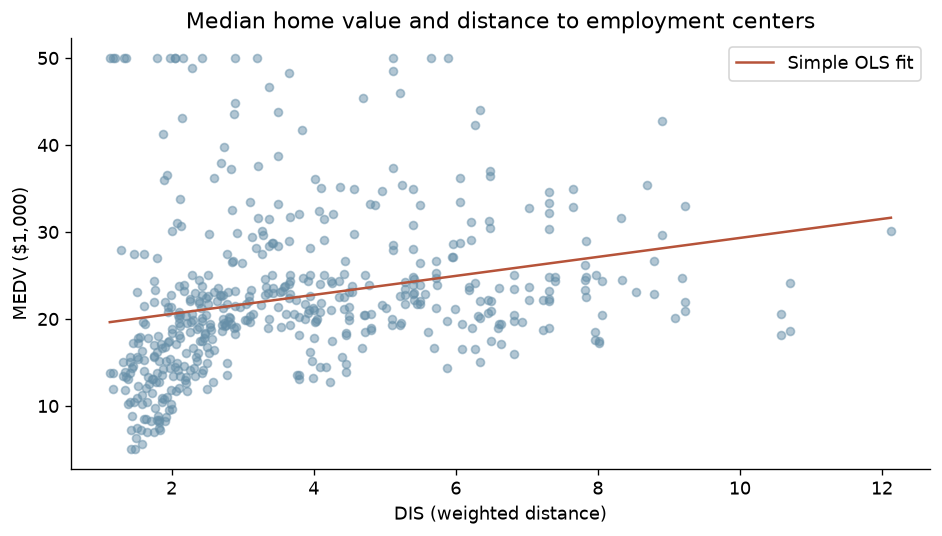

In [17]:
model = sm.OLS(boston_df.MEDV, sm.add_constant(boston_df[['DIS']])).fit()
print(model.summary().as_text())
slope = float(model.params['DIS'])
intercept = float(model.params['const'])
slope_ci = model.conf_int().loc['DIS']
print(f'Equation: predicted MEDV = {intercept:.6f} + {slope:.6f} * DIS.')
print(f'Slope p={model.pvalues["DIS"]:.8g}; 95% CI=[{slope_ci.iloc[0]:.6f}, {slope_ci.iloc[1]:.6f}]; R-squared={model.rsquared:.6f}.')
print(f'An additional unit of weighted distance is associated with about ${slope*1000:,.0f} higher tract median value on average in this unadjusted model.')
print(f'The model explains only {100*model.rsquared:.2f}% of MEDV variation. Reject a zero slope, but avoid claiming that distance itself raises prices.')
robust = model.get_robustcov_results(cov_type='HC3')
print(f'HC3 heteroskedasticity-robust slope p={robust.pvalues[1]:.8g}; the direction and significance decision are unchanged.')
fig, ax = plt.subplots()
ax.scatter(boston_df.DIS, boston_df.MEDV, alpha=.5, s=23, color='#668FA8')
xline = np.linspace(boston_df.DIS.min(), boston_df.DIS.max(), 150)
ax.plot(xline, intercept+slope*xline, color='#B65339', label='Simple OLS fit')
ax.set(title='Median home value and distance to employment centers', xlabel='DIS (weighted distance)', ylabel='MEDV ($1,000)')
ax.legend()
fig.tight_layout()
plt.show()
results = {
    'rows': len(boston_df), 'variables': 13, 'missing': int(missing.sum()), 'duplicates': duplicates,
    'age_group_boundaries': ['AGE <= 35', '35 < AGE < 70', 'AGE >= 70'],
    'age_group_counts': {k: len(v) for k,v in zip(age_labels,age_groups)},
    'levene_chas_statistic': float(levene_chas.statistic), 'levene_chas_p': float(levene_chas.pvalue),
    'welch_t_statistic': float(ttest_chas.statistic), 'welch_t_p': float(ttest_chas.pvalue),
    'river_mean_difference': mean_diff, 'river_mean_difference_ci': [float(ci_chas.low),float(ci_chas.high)],
    'anova_age_F': float(anova_age.statistic), 'anova_age_p': float(anova_age.pvalue),
    'welch_anova_age_p': float(welch_age.pvalue),
    'pearson_nox_indus_r': float(pearson_nox.statistic), 'pearson_nox_indus_p': float(pearson_nox.pvalue),
    'regression_intercept': intercept, 'regression_DIS_slope': slope,
    'regression_DIS_p': float(model.pvalues['DIS']), 'regression_R2': float(model.rsquared),
    'regression_DIS_slope_ci': [float(x) for x in slope_ci], 'regression_HC3_slope_p': float(robust.pvalues[1])
}
print('All 16 explicitly listed case-scenario exercises have been executed.')

## Management interpretation
River-bounded tracts show higher average MEDV, and MEDV differs across the stated AGE groups.
Non-retail business land and NOX are strongly positively associated. Distance has a statistically
significant positive slope but weak explanatory power in the single-predictor model.
Use these as exploratory patterns when planning further investigation. Collect current data and
control relevant confounders before making causal claims or using this historical sample for decisions.
